In [1]:
# File Loading and Preprocessing
import pandas as pd

games_all = pd.read_csv("data/steam_games_clean.csv")
games = games_all.copy()

print(games.shape)
print(games.head())


games["tags"] = games["tags"].fillna("")

games["tag_set"] = games["tags"].apply(
    lambda tags: {tag.strip() for tag in tags.split(",") if tag.strip()}
)

# Keep games with at least one tag
games = games[games["tag_set"].map(len) > 0].copy()

print(games[["name", "tag_set"]].head())

(23500, 10)
    app_id                                   name estimated_owners  price  \
0   496350  Supipara - Chapter 1 Spring Has Come!        0 - 20000   5.24   
1  1934300                     Armored Brigade II        0 - 20000  35.99   
2  1025440                     Fantasy General II  100000 - 200000  13.99   
3   328460                                Redline        0 - 20000   1.04   
4  2403000                 Fantasy Amusement Park        0 - 20000   5.99   

   positive  negative  avg_hours  median_hours               genres  \
0       252         3   0.133333      0.133333            Adventure   
1       117        13  11.250000     20.883333  Simulation,Strategy   
2      1025       210   8.150000      0.866667             Strategy   
3        74        35   3.383333      3.383333        Action,Racing   
4         0         0   1.466667      1.600000               Casual   

                                                tags  
0                  Adventure,Visual Novel,A

In [2]:
import numpy as np
from sklearn.preprocessing import MultiLabelBinarizer

# Sample games so both methods use the same input
SAMPLE_SIZE = 1000
games = games.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)

# Convert each game's tags into a binary feature vector
# Example: {"Action", "RPG"} -> [1, 1, 0, ...]
mlb = MultiLabelBinarizer()
X = mlb.fit_transform(games["tag_set"]).astype(np.float32)

# Both HAC and K-Means will use Euclidean distance on X
# No Jaccard similarity/distance matrix is needed
print("Games:", X.shape[0])
print("Tag features:", X.shape[1])


Games: 1000
Tag features: 417


In [3]:
from sklearn.cluster import AgglomerativeClustering

# HAC: Euclidean distance between binary tag vectors
hac = AgglomerativeClustering(
    n_clusters=10,
    metric="euclidean",
    linkage="ward"
)

games["hac_cluster"] = hac.fit_predict(X)

print("HAC cluster sizes:")
print(games["hac_cluster"].value_counts().sort_index())


HAC cluster sizes:
hac_cluster
0    156
1     80
2    134
3     81
4    100
5    218
6     68
7     78
8     35
9     50
Name: count, dtype: int64


In [4]:
from sklearn.cluster import KMeans

# K-Means: uses Euclidean distance on the same X
kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
games["kmeans_cluster"] = kmeans.fit_predict(X)

print("K-Means cluster sizes:")
print(games["kmeans_cluster"].value_counts().sort_index())


K-Means cluster sizes:
kmeans_cluster
0    104
1     88
2     58
3    109
4    248
5     41
6     62
7    105
8    100
9     85
Name: count, dtype: int64


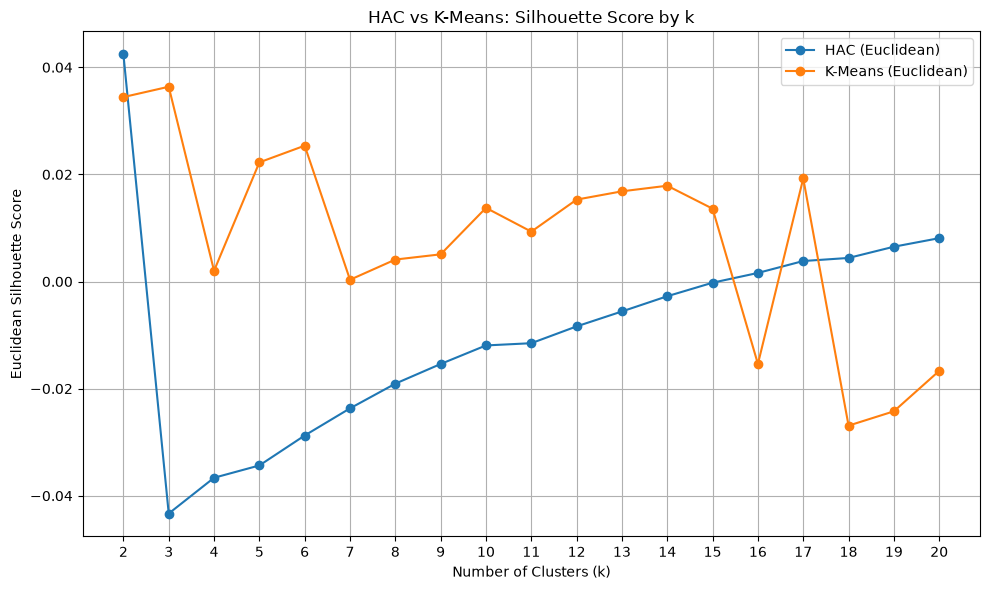

Best HAC k: 2, score: 0.0424
Best K-Means k: 3, score: 0.0364


In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

k_values = range(2, 21)
hac_scores = []
kmeans_scores = []

for k in k_values:
    # HAC on Euclidean tag vectors
    hac = AgglomerativeClustering(
        n_clusters=k,
        metric="euclidean",
        linkage="ward"
    )
    hac_labels = hac.fit_predict(X)

    # K-Means on the SAME Euclidean tag vectors
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_labels = kmeans.fit_predict(X)

    # Evaluate both with Euclidean silhouette scores
    hac_score = silhouette_score(X, hac_labels, metric="euclidean")
    kmeans_score = silhouette_score(X, kmeans_labels, metric="euclidean")

    hac_scores.append(hac_score)
    kmeans_scores.append(kmeans_score)

plt.style.use("default")
plt.figure(figsize=(10, 6))
plt.plot(k_values, hac_scores, marker="o", label="HAC (Euclidean)")
plt.plot(k_values, kmeans_scores, marker="o", label="K-Means (Euclidean)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Euclidean Silhouette Score")
plt.title("HAC vs K-Means: Silhouette Score by k")
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

best_hac_index = int(np.argmax(hac_scores))
best_kmeans_index = int(np.argmax(kmeans_scores))

print(f"Best HAC k: {list(k_values)[best_hac_index]}, score: {hac_scores[best_hac_index]:.4f}")
print(f"Best K-Means k: {list(k_values)[best_kmeans_index]}, score: {kmeans_scores[best_kmeans_index]:.4f}")


In [6]:
from sklearn.cluster import SpectralClustering

spectral = SpectralClustering(
    n_clusters=10,
    affinity="rbf",
    gamma=0.1,
    random_state=42,
    assign_labels="kmeans",
    n_init=10
)

games["spectral_cluster"] = spectral.fit_predict(X)

print("Spectral cluster sizes:")
print(games["spectral_cluster"].value_counts().sort_index())

Spectral cluster sizes:
spectral_cluster
0    105
1    258
2     75
3     96
4     72
5     68
6     70
7     88
8     80
9     88
Name: count, dtype: int64


In [7]:

spectral_scores = []

for k in k_values:
    spectral = SpectralClustering(
        n_clusters=k,
        affinity="rbf",
        gamma=0.1,
        random_state=42,
        assign_labels="kmeans",
        n_init=10
    )

    labels = spectral.fit_predict(X)

    score = silhouette_score(
        X, labels, metric="euclidean"
    )

    spectral_scores.append(score)


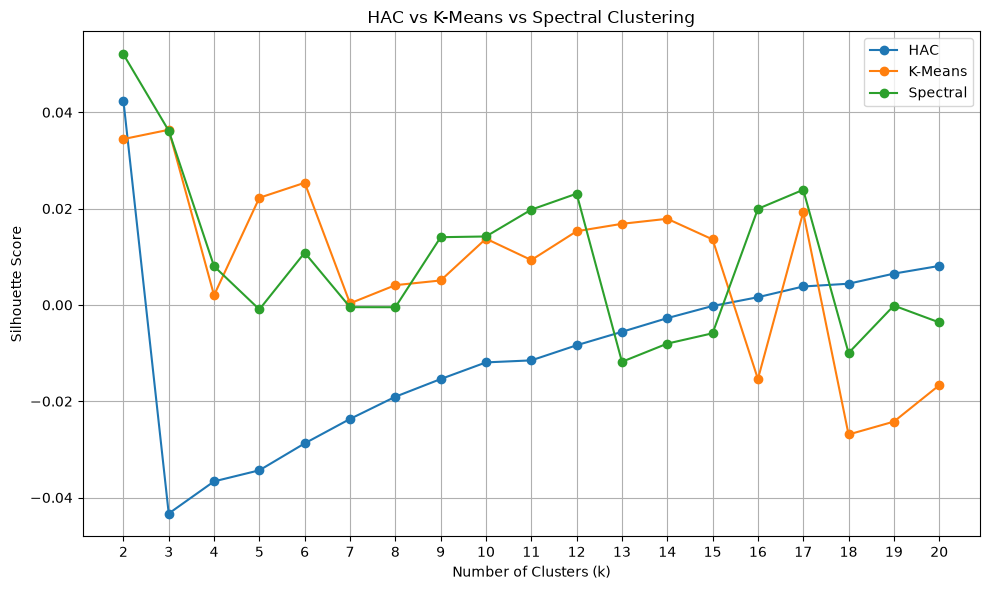

Best Spectral k: 2
Best Spectral score: 0.052


In [8]:

plt.figure(figsize=(10, 6))

plt.plot(k_values, hac_scores, marker="o", label="HAC")
plt.plot(k_values, kmeans_scores, marker="o", label="K-Means")
plt.plot(k_values, spectral_scores, marker="o", label="Spectral")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("HAC vs K-Means vs Spectral Clustering")

plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Best k
best_index = np.argmax(spectral_scores)
best_k = list(k_values)[best_index]

print("Best Spectral k:", best_k)
print("Best Spectral score:", round(spectral_scores[best_index], 4))


In [16]:
#Find the most common tags, number of games, median price, and median hours per dollar.


from collections import Counter

games["hours_per_dollar"] = games["avg_hours"] / games["price"]

# Cluster that is being used
method = "kmeans_cluster" # hac_cluster, spectral_cluster

for cluster_id, group in games.groupby(method):
    # Count tags in this cluster
    tag_counts = Counter()

    for tag_set in group["tag_set"]:
        for tag in tag_set:
            tag_counts[tag] += 1

    print(f"\nCluster {cluster_id}")
    print("Games:", len(group))
    print("Common tags:", tag_counts.most_common(5))
    print("Median price:", round(group["price"].median(), 2))
    print("Median hours:", round(group["avg_hours"].median(), 2))
    print("Median hours/$:", round(group["hours_per_dollar"].median(), 2))


Cluster 0
Games: 104
Common tags: [('Casual', 86), ('Singleplayer', 78), ('Family Friendly', 61), ('Indie', 58), ('Cute', 58)]
Median price: 3.24
Median hours: 3.15
Median hours/$: 1.13

Cluster 1
Games: 88
Common tags: [('Anime', 78), ('Visual Novel', 66), ('Singleplayer', 62), ('Adventure', 53), ('Sexual Content', 53)]
Median price: 5.04
Median hours: 3.62
Median hours/$: 0.86

Cluster 2
Games: 58
Common tags: [('RPG', 47), ('Singleplayer', 46), ('Strategy', 43), ('2D', 35), ('Turn-Based Combat', 33)]
Median price: 4.99
Median hours: 5.28
Median hours/$: 1.19

Cluster 3
Games: 109
Common tags: [('Action', 89), ('Singleplayer', 88), ('Adventure', 81), ('Open World', 63), ('Multiplayer', 58)]
Median price: 6.24
Median hours: 6.97
Median hours/$: 1.34

Cluster 4
Games: 248
Common tags: [('Indie', 162), ('Action', 114), ('Casual', 80), ('Adventure', 68), ('Simulation', 58)]
Median price: 2.99
Median hours: 2.64
Median hours/$: 0.8

Cluster 5
Games: 41
Common tags: [('Action', 39), ('Act

## Visualizing the clusters

PCA of binary tag features with fixed cluster counts: HAC k=19, K-Means k=17, and Spectral k=18.

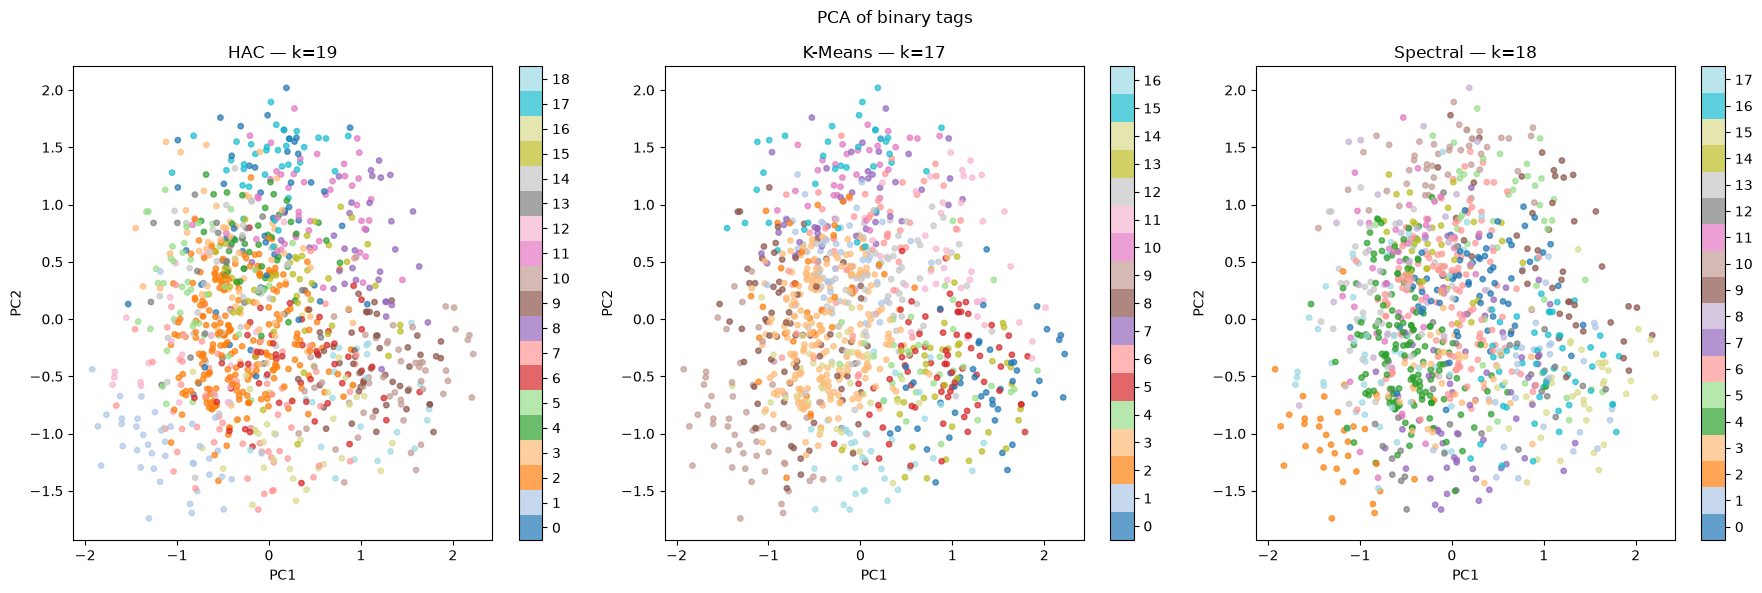

In [20]:
from sklearn.decomposition import PCA

# Match the cluster counts used in the TF-IDF comparison.
binary_best_k = {"HAC": 19, "K-Means": 17, "Spectral": 18}
binary_models = {
    "HAC": AgglomerativeClustering(
        n_clusters=binary_best_k["HAC"], metric="euclidean", linkage="ward"
    ),
    "K-Means": KMeans(n_clusters=binary_best_k["K-Means"], random_state=42, n_init=10),
    "Spectral": SpectralClustering(
        n_clusters=binary_best_k["Spectral"], affinity="rbf", gamma=0.1,
        random_state=42, assign_labels="kmeans", n_init=10,
    ),
}

pca = PCA(n_components=2, svd_solver="full")
Z = pca.fit_transform(X)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (method, model) in zip(axes, binary_models.items()):
    labels = model.fit_predict(X)
    k = binary_best_k[method]

    points = ax.scatter(
        Z[:, 0], Z[:, 1], c=labels,
        cmap=plt.get_cmap("tab20", k),
        vmin=-0.5, vmax=k - 0.5,
        s=15, alpha=0.7
    )

    ax.set_title(f"{method} — k={k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    fig.colorbar(points, ax=ax, ticks=range(k))

fig.suptitle("PCA of binary tags")
plt.tight_layout()
plt.show()


## Introducing Tfidf 

I was unsatisfied with the clustering, I realized all tags were weighted equally in this clustering. Some tags are more significant than others, and some are simply rarer than others.

We can look into implementing this or something similar, I am not sure how it affects the representation yet.

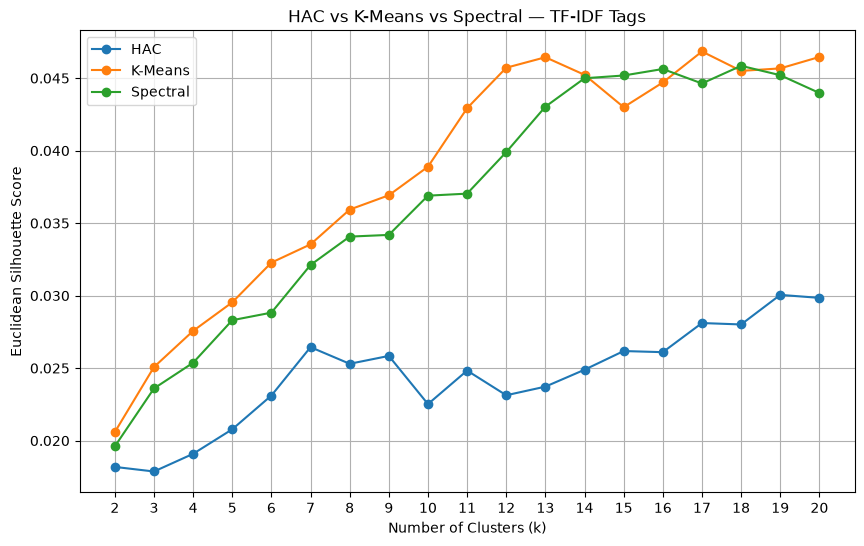

Best HAC k: 19, score: 0.0301
Best K-Means k: 17, score: 0.0468
Best Spectral k: 18, score: 0.0458


In [15]:
from sklearn.feature_extraction.text import TfidfTransformer


tfidf = TfidfTransformer()
X_tfidf = tfidf.fit_transform(X).toarray()

tfidf_scores = {"HAC": [], "K-Means": [], "Spectral": []}
for k in k_values:
    tfidf_models = {
        "HAC": AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage="ward"),
        "K-Means": KMeans(n_clusters=k, random_state=42, n_init=10),
        "Spectral": SpectralClustering(
            n_clusters=k, affinity="rbf", gamma=0.1,
            random_state=42, assign_labels="kmeans", n_init=10,
        ),
    }
    for method, model in tfidf_models.items():
        tfidf_labels = model.fit_predict(X_tfidf)
        tfidf_scores[method].append(
            silhouette_score(X_tfidf, tfidf_labels, metric="euclidean")
        )

plt.figure(figsize=(10, 6))
for method, scores in tfidf_scores.items():
    plt.plot(k_values, scores, marker="o", label=method)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Euclidean Silhouette Score")
plt.title("HAC vs K-Means vs Spectral — TF-IDF Tags")
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()

for method, scores in tfidf_scores.items():
    best_index = int(np.argmax(scores))
    print(f"Best {method} k: {list(k_values)[best_index]}, score: {scores[best_index]:.4f}")


## Visualizing the clusters
Below I ran PCA on the tfidf tags to see how they fit

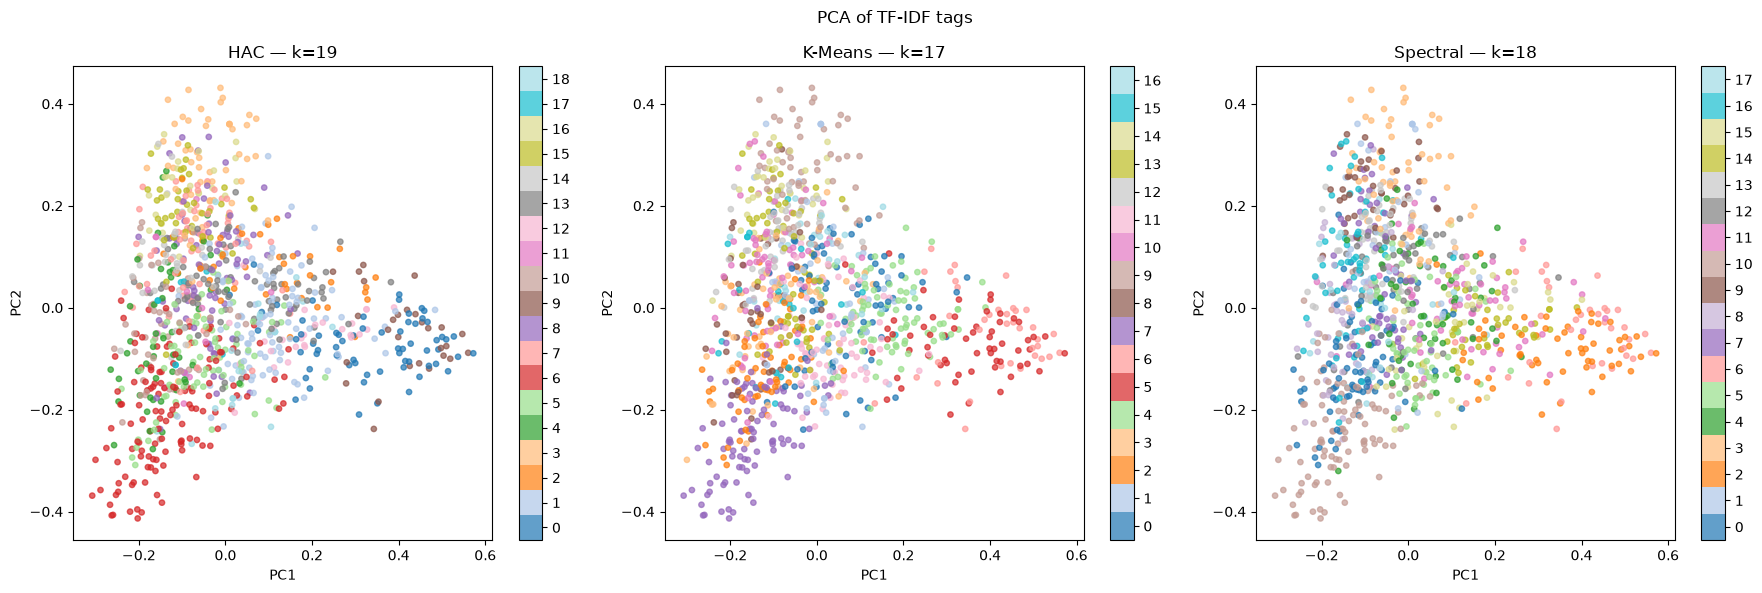

In [21]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, svd_solver="full")
Z = pca.fit_transform(X_tfidf)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (method, model) in zip(axes, models.items()):
    labels = model.fit_predict(X_tfidf)
    k = best_k[method]

    points = ax.scatter(
        Z[:, 0], Z[:, 1], c=labels,
        cmap=plt.get_cmap("tab20", k),
        vmin=-0.5, vmax=k - 0.5,
        s=15, alpha=0.7
    )

    ax.set_title(f"{method} — k={k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    fig.colorbar(points, ax=ax, ticks=range(k))

fig.suptitle("PCA of TF-IDF tags")
plt.tight_layout()
plt.show()